Project Title: Student Performance Analysis: Identifying the Key Factors Affecting Academic Results.

Project Objective: To analyze student data and identify which factors, such as parental education, gender, lunch type, test preparation, and ethnicity, are associated with students’ math, reading, and writing scores.

In [ ]:
#proj-->Student performance analysis

In [1]:
# import the files
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# read the data
df=pd.read_csv("https://github.com/Kalai865/Data_Analysis-Datasets/raw/refs/heads/main/student_data.csv")
df

,Unnamed: 0,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,1,female,group C,some college,standard,NaN,married,sometimes,yes,0.0,NaN,5 - 10,69,90,88
2,2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
3,3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,NaN,5 - 10,45,56,42
4,4,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10,76,78,75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30636,816,female,group D,high school,standard,none,single,sometimes,no,2.0,school_bus,5 - 10,59,61,65
30637,890,male,group E,high school,standard,none,single,regularly,no,1.0,private,5 - 10,58,53,51
30638,911,female,NaN,high school,free/reduced,completed,married,sometimes,no,1.0,private,5 - 10,61,70,67
30639,934,female,group D,associate's degree,standard,completed,married,regularly,no,3.0,school_bus,5 - 10,82,90,93


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30641 entries, 0 to 30640
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           30641 non-null  int64  
 1   Gender               30641 non-null  object 
 2   EthnicGroup          28801 non-null  object 
 3   ParentEduc           28796 non-null  object 
 4   LunchType            30641 non-null  object 
 5   TestPrep             28811 non-null  object 
 6   ParentMaritalStatus  29451 non-null  object 
 7   PracticeSport        30010 non-null  object 
 8   IsFirstChild         29737 non-null  object 
 9   NrSiblings           29069 non-null  float64
 10  TransportMeans       27507 non-null  object 
 11  WklyStudyHours       29686 non-null  object 
 12  MathScore            30641 non-null  int64  
 13  ReadingScore         30641 non-null  int64  
 14  WritingScore         30641 non-null  int64  
dtypes: float64(1), int64(4), object(10)


In [4]:
df.columns

Index(['Unnamed: 0', 'Gender', 'EthnicGroup', 'ParentEduc', 'LunchType',
       'TestPrep', 'ParentMaritalStatus', 'PracticeSport', 'IsFirstChild',
       'NrSiblings', 'TransportMeans', 'WklyStudyHours', 'MathScore',
       'ReadingScore', 'WritingScore'],
      dtype='object')

In [7]:
# droping the 'Unnamed: 0' column because its unwanted
df=df.drop(['Unnamed: 0'],axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30641 entries, 0 to 30640
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               30641 non-null  object 
 1   EthnicGroup          28801 non-null  object 
 2   ParentEduc           28796 non-null  object 
 3   LunchType            30641 non-null  object 
 4   TestPrep             28811 non-null  object 
 5   ParentMaritalStatus  29451 non-null  object 
 6   PracticeSport        30010 non-null  object 
 7   IsFirstChild         29737 non-null  object 
 8   NrSiblings           29069 non-null  float64
 9   TransportMeans       27507 non-null  object 
 10  WklyStudyHours       29686 non-null  object 
 11  MathScore            30641 non-null  int64  
 12  ReadingScore         30641 non-null  int64  
 13  WritingScore         30641 non-null  int64  
dtypes: float64(1), int64(3), object(10)
memory usage: 3.3+ MB


In [8]:
# checking null values in whole datset
df.isnull().sum()

,0
Gender,0
EthnicGroup,1840
ParentEduc,1845
LunchType,0
TestPrep,1830
ParentMaritalStatus,1190
PracticeSport,631
IsFirstChild,904
NrSiblings,1572
TransportMeans,3134


In [9]:
# handling the null value with dropna()
df.dropna(inplace=True)
df.isnull().sum()

,0
Gender,0
EthnicGroup,0
ParentEduc,0
LunchType,0
TestPrep,0
ParentMaritalStatus,0
PracticeSport,0
IsFirstChild,0
NrSiblings,0
TransportMeans,0


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19243 entries, 2 to 30640
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               19243 non-null  object 
 1   EthnicGroup          19243 non-null  object 
 2   ParentEduc           19243 non-null  object 
 3   LunchType            19243 non-null  object 
 4   TestPrep             19243 non-null  object 
 5   ParentMaritalStatus  19243 non-null  object 
 6   PracticeSport        19243 non-null  object 
 7   IsFirstChild         19243 non-null  object 
 8   NrSiblings           19243 non-null  float64
 9   TransportMeans       19243 non-null  object 
 10  WklyStudyHours       19243 non-null  object 
 11  MathScore            19243 non-null  int64  
 12  ReadingScore         19243 non-null  int64  
 13  WritingScore         19243 non-null  int64  
dtypes: float64(1), int64(3), object(10)
memory usage: 2.2+ MB


In [11]:
# cheking duplicate values
df.duplicated().sum()

np.int64(0)

In [12]:
df

,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
4,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10,76,78,75
5,female,group B,associate's degree,standard,none,married,regularly,yes,1.0,school_bus,5 - 10,73,84,79
6,female,group B,some college,standard,completed,widowed,never,no,1.0,private,5 - 10,85,93,89
7,male,group B,some college,free/reduced,none,married,sometimes,yes,1.0,private,> 10,41,43,39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30635,male,group C,some college,standard,none,married,regularly,no,2.0,school_bus,5 - 10,58,53,49
30636,female,group D,high school,standard,none,single,sometimes,no,2.0,school_bus,5 - 10,59,61,65
30637,male,group E,high school,standard,none,single,regularly,no,1.0,private,5 - 10,58,53,51
30639,female,group D,associate's degree,standard,completed,married,regularly,no,3.0,school_bus,5 - 10,82,90,93


In [13]:
# reset the index
df.reset_index(inplace=True)

In [14]:
df

,index,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
1,4,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10,76,78,75
2,5,female,group B,associate's degree,standard,none,married,regularly,yes,1.0,school_bus,5 - 10,73,84,79
3,6,female,group B,some college,standard,completed,widowed,never,no,1.0,private,5 - 10,85,93,89
4,7,male,group B,some college,free/reduced,none,married,sometimes,yes,1.0,private,> 10,41,43,39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19238,30635,male,group C,some college,standard,none,married,regularly,no,2.0,school_bus,5 - 10,58,53,49
19239,30636,female,group D,high school,standard,none,single,sometimes,no,2.0,school_bus,5 - 10,59,61,65
19240,30637,male,group E,high school,standard,none,single,regularly,no,1.0,private,5 - 10,58,53,51
19241,30639,female,group D,associate's degree,standard,completed,married,regularly,no,3.0,school_bus,5 - 10,82,90,93


In [15]:
df=df.drop(['index'],axis=1)
df

,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
1,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10,76,78,75
2,female,group B,associate's degree,standard,none,married,regularly,yes,1.0,school_bus,5 - 10,73,84,79
3,female,group B,some college,standard,completed,widowed,never,no,1.0,private,5 - 10,85,93,89
4,male,group B,some college,free/reduced,none,married,sometimes,yes,1.0,private,> 10,41,43,39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19238,male,group C,some college,standard,none,married,regularly,no,2.0,school_bus,5 - 10,58,53,49
19239,female,group D,high school,standard,none,single,sometimes,no,2.0,school_bus,5 - 10,59,61,65
19240,male,group E,high school,standard,none,single,regularly,no,1.0,private,5 - 10,58,53,51
19241,female,group D,associate's degree,standard,completed,married,regularly,no,3.0,school_bus,5 - 10,82,90,93


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19243 entries, 0 to 19242
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               19243 non-null  object 
 1   EthnicGroup          19243 non-null  object 
 2   ParentEduc           19243 non-null  object 
 3   LunchType            19243 non-null  object 
 4   TestPrep             19243 non-null  object 
 5   ParentMaritalStatus  19243 non-null  object 
 6   PracticeSport        19243 non-null  object 
 7   IsFirstChild         19243 non-null  object 
 8   NrSiblings           19243 non-null  float64
 9   TransportMeans       19243 non-null  object 
 10  WklyStudyHours       19243 non-null  object 
 11  MathScore            19243 non-null  int64  
 12  ReadingScore         19243 non-null  int64  
 13  WritingScore         19243 non-null  int64  
dtypes: float64(1), int64(3), object(10)
memory usage: 2.1+ MB


Now I  have the cleaned dataset

In [18]:
df.columns

Index(['Gender', 'EthnicGroup', 'ParentEduc', 'LunchType', 'TestPrep',
       'ParentMaritalStatus', 'PracticeSport', 'IsFirstChild', 'NrSiblings',
       'TransportMeans', 'WklyStudyHours', 'MathScore', 'ReadingScore',
       'WritingScore'],
      dtype='object')

In [19]:
# analysis of student marks with respect to ethenicgroupp
# creating the pivot table
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index='EthnicGroup'
)
eg

,MathScore,ReadingScore,WritingScore
EthnicGroup,,,
group A,63.092150,66.715358,65.088055
group B,63.565262,67.339208,65.978544
group C,64.674163,68.578709,67.178774
group D,67.823742,70.608652,71.140040
group E,75.274336,74.435103,72.886062


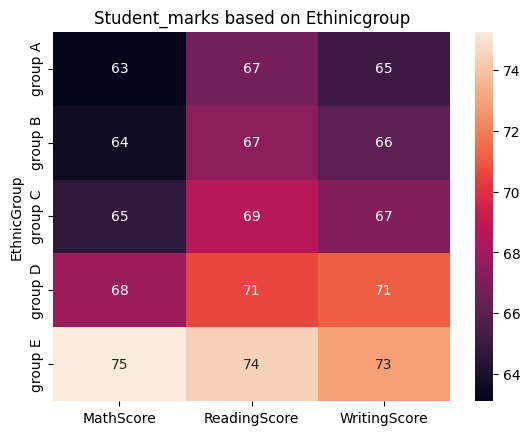

In [20]:
# with the help of heatmap we can analyze the data
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on Ethinicgroup')
plt.show()

Group E and Group D students are scoring good marks (according to above analysis)

In [21]:
df.columns

Index(['Gender', 'EthnicGroup', 'ParentEduc', 'LunchType', 'TestPrep',
       'ParentMaritalStatus', 'PracticeSport', 'IsFirstChild', 'NrSiblings',
       'TransportMeans', 'WklyStudyHours', 'MathScore', 'ReadingScore',
       'WritingScore'],
      dtype='object')

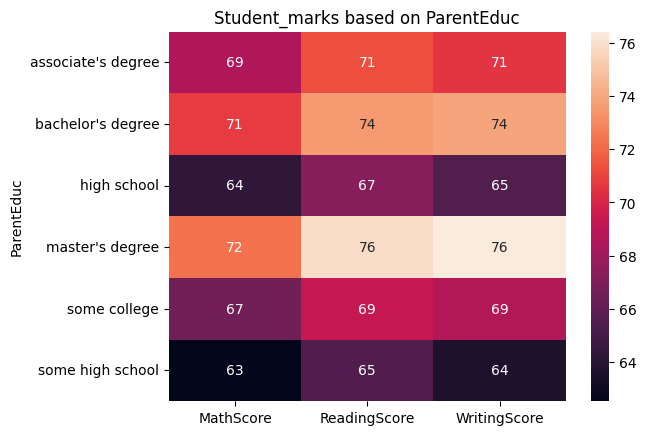

In [22]:
# # analysis of student marks with respect to parents education
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index='ParentEduc'
)

#  analyze the data with heatmap
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on ParentEduc')
plt.show()



If The parents did masteers or bachelors , their childrens are gettig good marks

In [23]:
df.columns

Index(['Gender', 'EthnicGroup', 'ParentEduc', 'LunchType', 'TestPrep',
       'ParentMaritalStatus', 'PracticeSport', 'IsFirstChild', 'NrSiblings',
       'TransportMeans', 'WklyStudyHours', 'MathScore', 'ReadingScore',
       'WritingScore'],
      dtype='object')

In [25]:
df["LunchType"].unique()

array(['standard', 'free/reduced'], dtype=object)

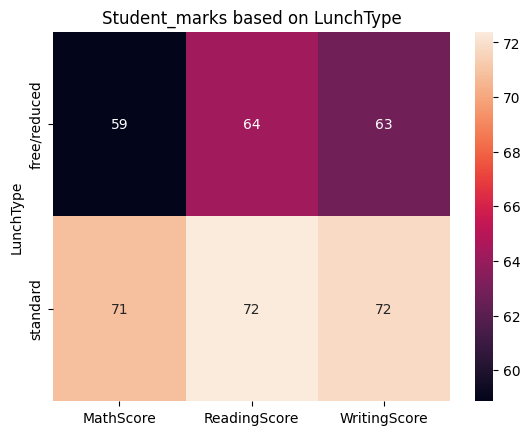

In [26]:
# # analysis of student marks with respect to LunchType
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index='LunchType'
)

#  analyze the data with heatmap
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on LunchType')
plt.show()


if the students who eat standard lunch getting good marks

In [27]:
df['TestPrep'].unique()


array(['none', 'completed'], dtype=object)

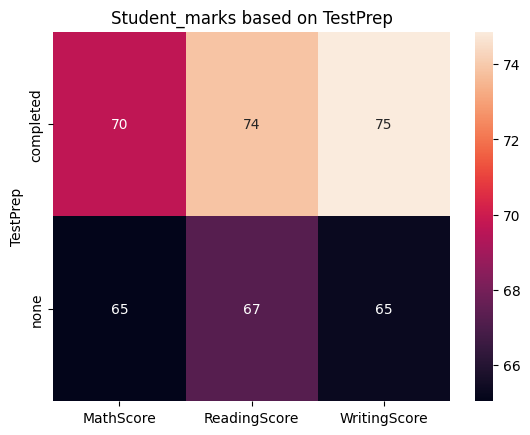

In [28]:
# # analysis of student marks with respect to 'TestPrep'
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index= 'TestPrep'
)

# analyze the data with heatmap
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on TestPrep')
plt.show()

Test preparation completed students are scoring good marks

In [29]:
df['ParentMaritalStatus'].unique()


array(['single', 'married', 'widowed', 'divorced'], dtype=object)

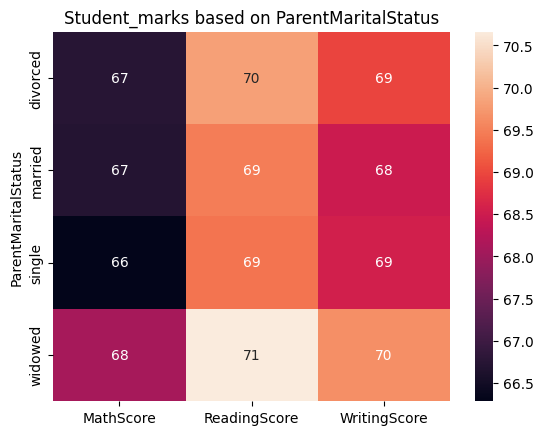

In [30]:
# # analysis of student marks with respect to ParentMaritalStatus
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index= 'ParentMaritalStatus'
)

# analyze the data with heatmap
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on ParentMaritalStatus')
plt.show()

Student marks is not depending on the perents marital stauts

In [31]:
df['PracticeSport'].unique()


array(['sometimes', 'regularly', 'never'], dtype=object)

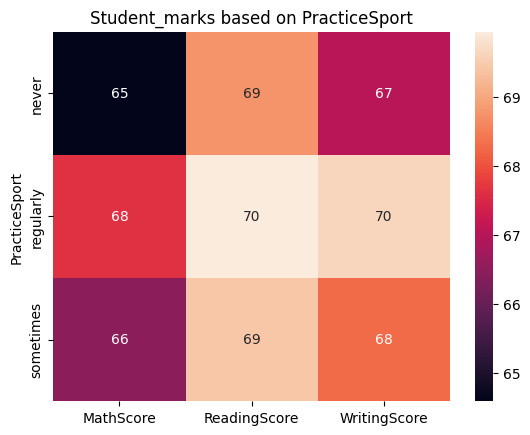

In [32]:
# # analysis of student marks with respect to 'PracticeSport'
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index= 'PracticeSport'
)

# analyze the data with heatmap
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on PracticeSport')
plt.show()

student who practice sports regularly are scoring more marks

In [33]:
df['IsFirstChild'].unique()


array(['yes', 'no'], dtype=object)

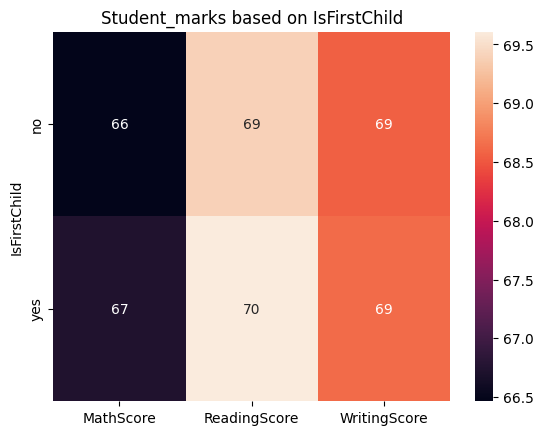

In [34]:
# # analysis of student marks with respect to 'IsFirstChild'
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index= 'IsFirstChild'
)
# analyze the data with heatmap
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on IsFirstChild')
plt.show()

whether the student is fisrtchild or not it not affecting the student marks

In [35]:
df['NrSiblings'].unique()


array([4., 0., 1., 3., 2., 5., 7., 6.])

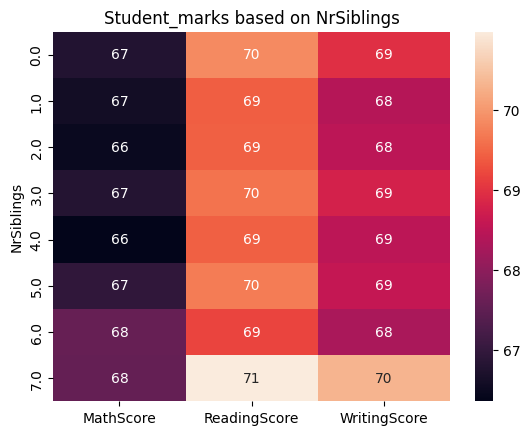

In [36]:
# # analysis of student marks with respect to 'NrSiblings'
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index= 'NrSiblings'
)

# analyze the data with heatmap
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on NrSiblings')
plt.show()

exam score does not affect the marks of the students

In [37]:
df.columns

Index(['Gender', 'EthnicGroup', 'ParentEduc', 'LunchType', 'TestPrep',
       'ParentMaritalStatus', 'PracticeSport', 'IsFirstChild', 'NrSiblings',
       'TransportMeans', 'WklyStudyHours', 'MathScore', 'ReadingScore',
       'WritingScore'],
      dtype='object')

In [38]:
df['TransportMeans'].unique()

array(['school_bus', 'private'], dtype=object)

In [45]:
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index='TransportMeans'
)
eg

,MathScore,ReadingScore,WritingScore
TransportMeans,,,
private,66.518900,69.520030,68.590481
school_bus,66.717819,69.544415,68.611613


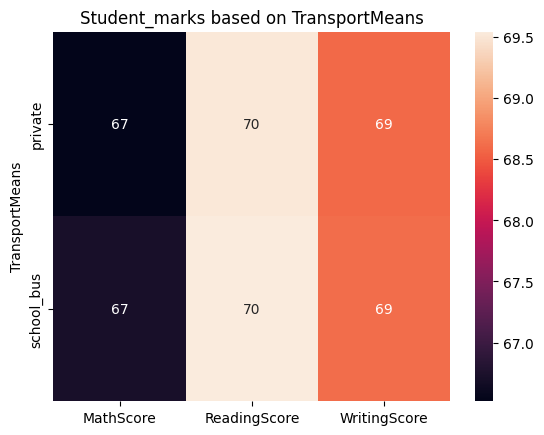

In [43]:
# # analysis of student marks with respect to 'TransportMeans'
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index= 'TransportMeans'
)

# analyze the data with heatmap
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on TransportMeans')
plt.show()

the result doesnt depend on transport or the trasportmeans is also not affect the student marks

In [46]:
df['WklyStudyHours'].unique()


array(['< 5', '5 - 10', '> 10'], dtype=object)

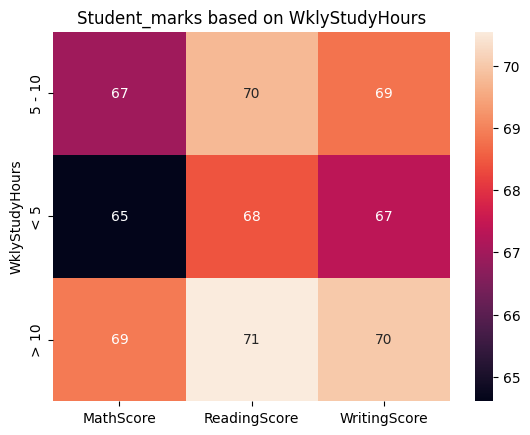

In [47]:
# # analysis of student marks with respect to 'WklyStudyHours'
eg=df.pivot_table(
    values=['MathScore', 'ReadingScore','WritingScore'],
    index= 'WklyStudyHours'
)

# analyze the data with heatmap
sns.heatmap(eg,annot=True)
plt.title('Student_marks based on WklyStudyHours')
plt.show()

The students who studied 5 to 10 or more thean that are scoring good marks

In [ ]:
# final conclusion

#**The student who are studing in group D and E where whose parents are having bachlors or masters degree and those who are practising sports regularly and having standard food and atuding 5 to 10 or more then that are scoring good marks **